In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset - replace with your actual filename
df = pd.read_csv('student-mat.csv', sep=';')

# Create the target used by the class-distribution cell
df['performance_category'] = pd.cut(
    df['G3'],
    bins=[-1, 9, 14, 20],
    labels=['Low', 'Average', 'High']
)

# Check the first few rows to see the structure
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,performance_category
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,Low
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,Low
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,Average
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,High
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,Average


In [2]:
# 1. How big is the dataset? (rows, columns)
print("Shape of the data:", df.shape)

# 2. What are the data types and are there missing values?
df.info()

# 3. Get a statistical summary of numerical columns
df.describe()

# 4. Check for missing values in each column
print(df.isnull().sum())

Shape of the data: (395, 34)
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 34 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   school                395 non-null    str     
 1   sex                   395 non-null    str     
 2   age                   395 non-null    int64   
 3   address               395 non-null    str     
 4   famsize               395 non-null    str     
 5   Pstatus               395 non-null    str     
 6   Medu                  395 non-null    int64   
 7   Fedu                  395 non-null    int64   
 8   Mjob                  395 non-null    str     
 9   Fjob                  395 non-null    str     
 10  reason                395 non-null    str     
 11  guardian              395 non-null    str     
 12  traveltime            395 non-null    int64   
 13  studytime             395 non-null    int64   
 14  failures              395 non-null    in

performance_category
Average    192
Low        130
High        73
Name: count, dtype: int64


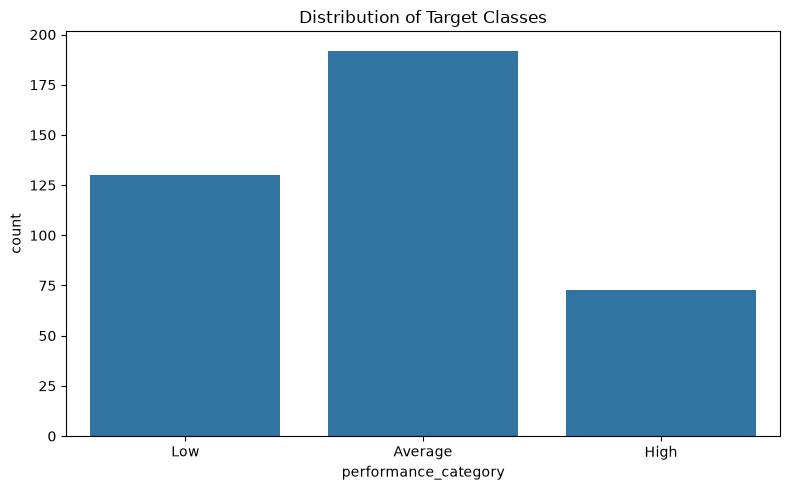

In [3]:
%matplotlib inline
# Check the distribution of your target classes
print(df['performance_category'].value_counts())

# Visualize the class balance
from IPython.display import display
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(x='performance_category', data=df, ax=ax)
ax.set_title('Distribution of Target Classes')
fig.tight_layout()
display(fig)
plt.close(fig)

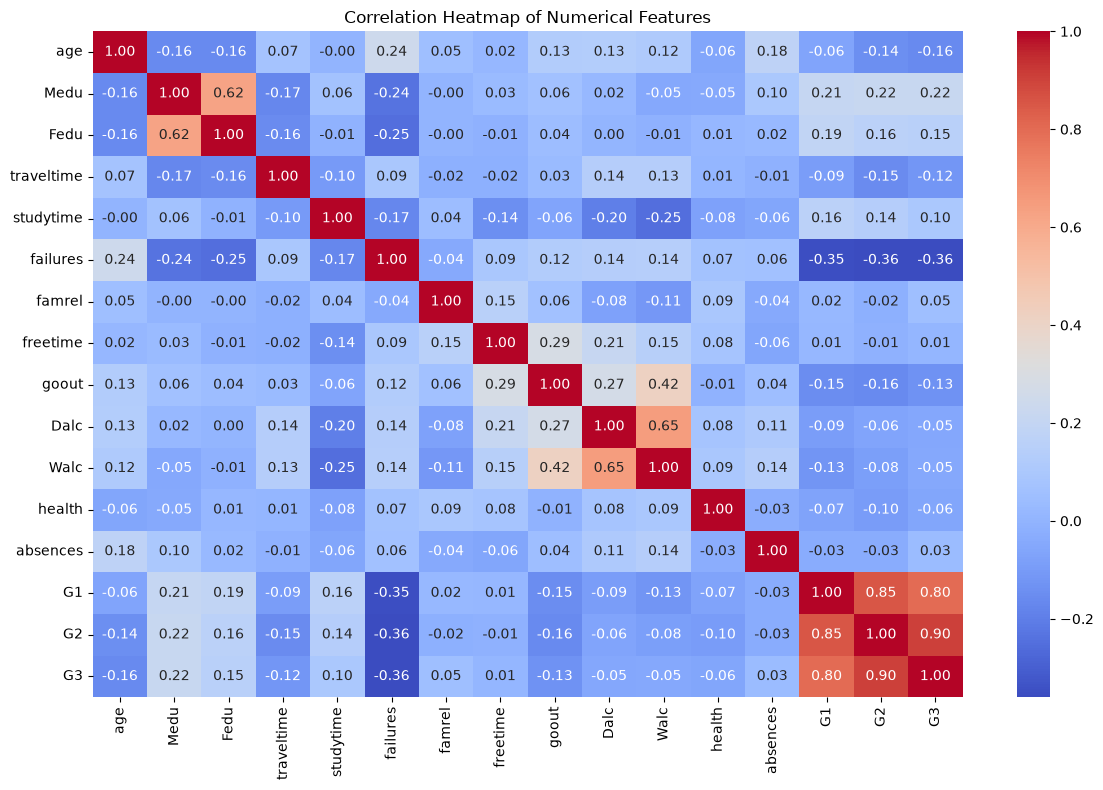

In [4]:
%matplotlib inline
# Reload the data here so this block works even if earlier cells were skipped
df = pd.read_csv('student-mat.csv', sep=';')
df['performance_category'] = pd.cut(
    df['G3'],
    bins=[-1, 9, 14, 20],
    labels=['Low', 'Average', 'High']
)

numerical_df = df.select_dtypes(include='number')
if numerical_df.empty:
    raise ValueError('No numerical columns were found in the dataset.')

correlation = numerical_df.corr()
if correlation.empty:
    raise ValueError('The correlation matrix is empty.')

from IPython.display import display
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
ax.set_title('Correlation Heatmap of Numerical Features')
fig.tight_layout()
display(fig)
plt.close(fig)

# Preprocessing and Feature Engineering

In [5]:
# Example: Convert a numeric final grade into 3 performance classes
# Adjust thresholds based on your dataset's scale
def categorize_grade(score):
    if score >= 15:
        return 'High'
    elif score >= 10:
        return 'Medium'
    else:
        return 'Low'

df['performance'] = df['G3'].apply(categorize_grade)

# Check the new class distribution
print(df['performance'].value_counts())

performance
Medium    192
Low       130
High       73
Name: count, dtype: int64


In [6]:
# Drop the target and any leaky columns
X = df.drop(columns=['performance', 'performance_category', 'G2', 'G3'])  # exclude target and current/final grade leakage
y = df['performance']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (395, 31)
Target shape: (395,)


In [7]:
# Numeric columns: fill with median
numeric_cols = X.select_dtypes(include=[np.number]).columns
X[numeric_cols] = X[numeric_cols].fillna(X[numeric_cols].median())

# Categorical columns: fill with mode
categorical_cols = X.select_dtypes(include=['object', 'string', 'category']).columns
for col in categorical_cols:
    X[col] = X[col].fillna(X[col].mode()[0])

print("Remaining missing values:", X.isnull().sum().sum())

Remaining missing values: 0


In [8]:
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print("Shape after encoding:", X.shape)

Shape after encoding: (395, 40)


In [9]:
# Do not derive features from G2 because it is excluded to avoid grade leakage.

# Data Splitting 

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (316, 40)
Test set: (79, 40)


In [11]:
from sklearn.preprocessing import StandardScaler

# Encode any categorical columns that remain in the train/test data
X_train_encoded = pd.get_dummies(X_train, dtype=float)
X_test_encoded = pd.get_dummies(X_test, dtype=float)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled test data:", X_test_scaled.shape)

Scaled training data: (316, 40)
Scaled test data: (79, 40)


#  Train Your First Classifier

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Baseline 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
log_preds = log_model.predict(X_test_scaled)

# Baseline 2: Decision Tree (uses the same encoded features)
tree_model = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_model.fit(X_train_encoded, y_train)
tree_preds = tree_model.predict(X_test_encoded)

===== Logistic Regression =====
Accuracy: 0.6835

Classification Report:
               precision    recall  f1-score   support

        High       0.62      0.67      0.65        15
         Low       0.70      0.81      0.75        26
      Medium       0.70      0.61      0.65        38

    accuracy                           0.68        79
   macro avg       0.67      0.69      0.68        79
weighted avg       0.68      0.68      0.68        79



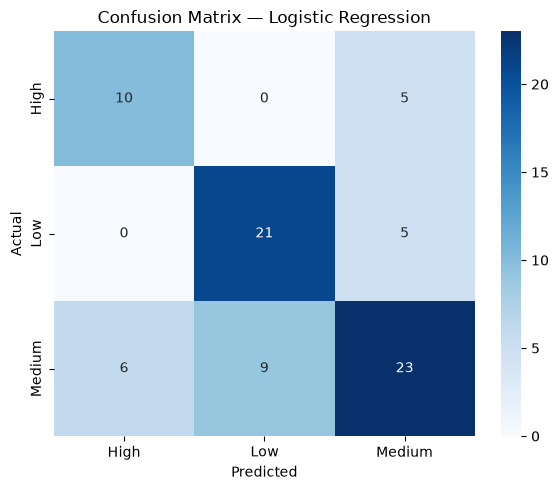

===== Decision Tree =====
Accuracy: 0.8101

Classification Report:
               precision    recall  f1-score   support

        High       0.76      0.87      0.81        15
         Low       0.81      0.85      0.83        26
      Medium       0.83      0.76      0.79        38

    accuracy                           0.81        79
   macro avg       0.80      0.83      0.81        79
weighted avg       0.81      0.81      0.81        79



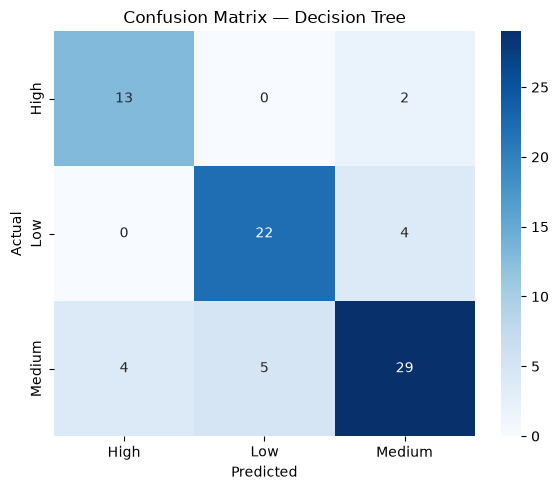

In [13]:
%matplotlib inline
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

def evaluate_model(name, y_true, y_pred):
    print(f"===== {name} =====")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("\nClassification Report:\n", classification_report(y_true, y_pred))
    
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=log_model.classes_,
                yticklabels=log_model.classes_, ax=ax)
    ax.set_title(f'Confusion Matrix — {name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    fig.tight_layout()
    display(fig)
    plt.close(fig)

evaluate_model("Logistic Regression", y_test, log_preds)
evaluate_model("Decision Tree", y_test, tree_preds)

#  Random Forest

===== Random Forest =====
Accuracy: 0.7089



Classification Report:
               precision    recall  f1-score   support

        High       0.88      0.47      0.61        15
         Low       0.88      0.54      0.67        26
      Medium       0.64      0.92      0.75        38

    accuracy                           0.71        79
   macro avg       0.80      0.64      0.68        79
weighted avg       0.76      0.71      0.70        79



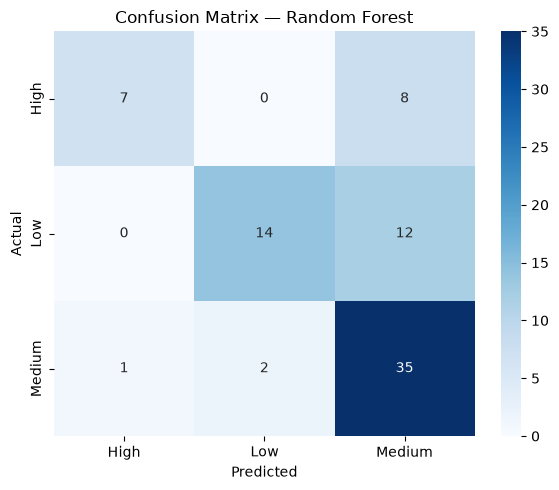

In [14]:
from sklearn.ensemble import RandomForestClassifier

# Create and train the model
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train_encoded, y_train)

# Predict and evaluate
rf_preds = rf_model.predict(X_test_encoded)

# Run your evaluation function
evaluate_model("Random Forest", y_test, rf_preds)

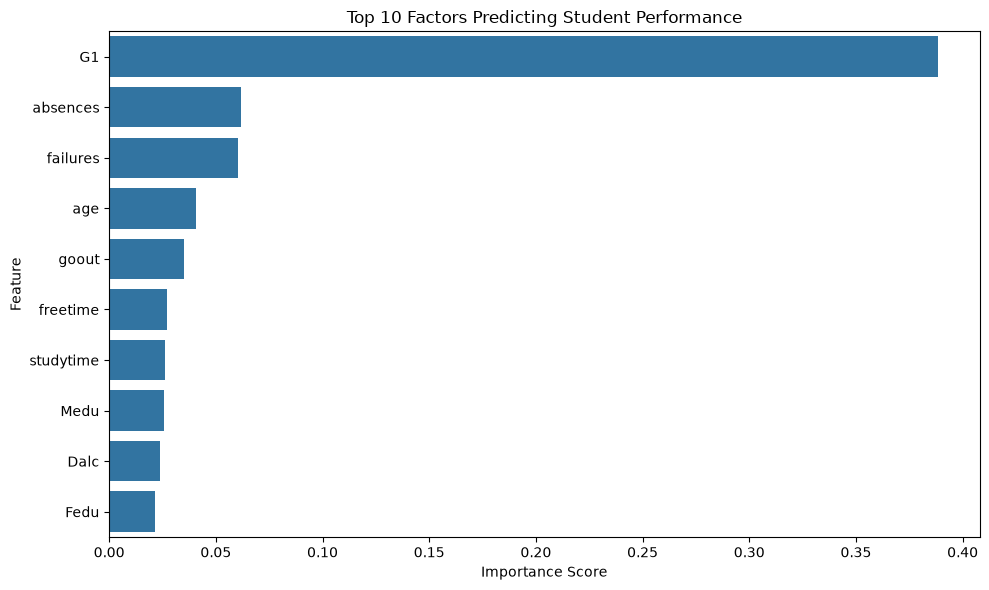

In [15]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

# Get feature importances from the Random Forest
try:
    check_is_fitted(rf_model)
except NotFittedError:
    print('Random Forest is not fitted; fitting it on the training data.')
    rf_model.fit(X_train_encoded, y_train)
importances = rf_model.feature_importances_

# Put them in a DataFrame for easy viewing
feature_imp = pd.Series(importances, index=X_train_encoded.columns).sort_values(ascending=False)

# Plot the top 10 most important features
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=feature_imp.head(10).values, y=feature_imp.head(10).index, ax=ax)
ax.set_title('Top 10 Factors Predicting Student Performance')
ax.set_xlabel('Importance Score')
ax.set_ylabel('Feature')
fig.tight_layout()
from IPython.display import display
display(fig)
plt.close(fig)

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Define the grid of settings to test
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10]
}

# Set up the search
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5)
grid_search.fit(X_train_encoded, y_train)

print(f"Best Settings found: {grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

Best Settings found: {'max_depth': 3, 'min_samples_split': 2}
Best Cross-Validation Accuracy: 0.7245


In [17]:
from importlib.util import find_spec

if find_spec('streamlit') is None:
    print('Optional Streamlit UI skipped; install streamlit to run this app.')
else:
    import streamlit as st

    st.title("🎓 Student Performance Predictor")
    st.write("Enter the student's details below to predict their final performance category.")

    absences = st.slider("Number of Absences", 0, 30, 5)
    studytime = st.slider("Weekly Study Time (1-4)", 1, 4, 2)
    failures = st.slider("Past Class Failures", 0, 4, 0)
    g1 = st.slider("First Period Grade (G1)", 0, 20, 10)

    print('Create a feature row matching X_train_encoded.columns before calling rf_model.predict().')

Optional Streamlit UI skipped; install streamlit to run this app.


===== Random Forest (Balanced) =====
Accuracy: 0.7342

Classification Report:
               precision    recall  f1-score   support

        High       0.67      0.93      0.78        15
         Low       0.69      0.92      0.79        26
      Medium       0.87      0.53      0.66        38

    accuracy                           0.73        79
   macro avg       0.74      0.79      0.74        79
weighted avg       0.77      0.73      0.72        79



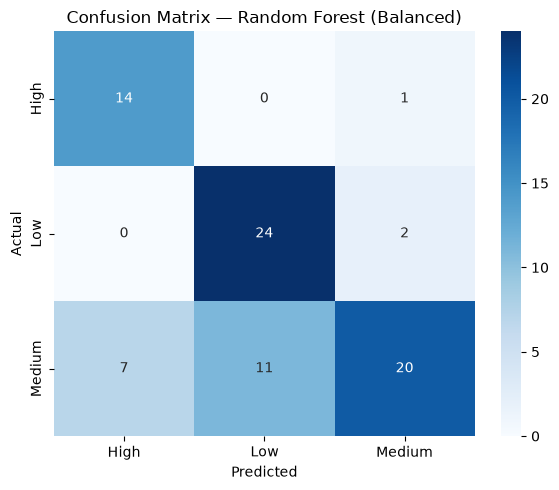

In [18]:
# Add class_weight='balanced' to the model
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, class_weight='balanced')
rf_model.fit(X_train_encoded, y_train)
rf_preds = rf_model.predict(X_test_encoded)

evaluate_model("Random Forest (Balanced)", y_test, rf_preds)

In [19]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Cross-validate using encoded training data; keep the held-out test set untouched
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_scores = cross_val_score(dt, X_train_encoded, y_train, cv=5)
print(f"Decision Tree 5-fold CV accuracy: {dt_scores.mean()*100:.2f}%")

# Cross-validate the Random Forest on the same training folds
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_scores = cross_val_score(rf, X_train_encoded, y_train, cv=5)
print(f"Random Forest 5-fold CV accuracy: {rf_scores.mean()*100:.2f}%")

Decision Tree 5-fold CV accuracy: 69.31%


Random Forest 5-fold CV accuracy: 69.28%


# Feature Extraction

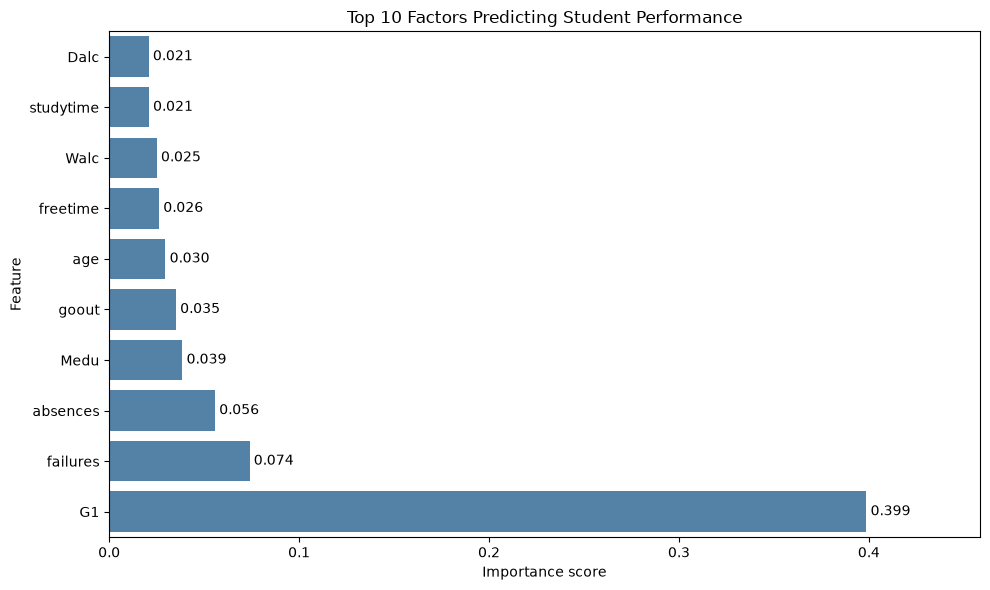

In [20]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

try:
    check_is_fitted(rf_model)
except NotFittedError:
    print('Random Forest is not fitted; fitting it on the training data.')
    rf_model.fit(X_train_encoded, y_train)

feature_imp = pd.Series(rf_model.feature_importances_, index=X_train_encoded.columns).sort_values(ascending=False)
top_features = feature_imp.head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index, color='steelblue', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.3f', padding=3)
ax.set_xlim(0, top_features.max() * 1.15)
ax.set_title('Top 10 Factors Predicting Student Performance')
ax.set_xlabel('Importance score')
ax.set_ylabel('Feature')
fig.tight_layout()
from IPython.display import display
display(fig)
plt.close(fig)

In [21]:
import pickle

# Save the model to a file
with open('student_model.pkl', 'wb') as file:
    pickle.dump(rf_model, file)
    
print("Model saved successfully!")

Model saved successfully!


In [22]:
import pickle

# 1. Save the trained Random Forest model
with open('model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

# 2. Save the StandardScaler (assuming you named it 'scaler' when you scaled X)
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# 3. Save the exact encoded feature names used to train the model
# (This is crucial because one-hot encoding changes the number of columns)
with open('columns.pkl', 'wb') as f:
    pickle.dump(X_train_encoded.columns.tolist(), f)

print("Models saved successfully!")

Models saved successfully!
